In [1]:
# Import the libraries
import kagglehub
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
import importlib
import utils
importlib.reload(utils)
from utils import (brand_variant_rules, extract_variant, normalize_variant, get_state_name, get_no_of_owners, 
get_final_dataset)

### Dataset-4

In [2]:
# Import the fourth dataset from kaggle
path = kagglehub.dataset_download("sukritchatterjee/used-cars-dataset-cardekho", 
                                  output_dir=r".\Raw Datasets\Cardekho")
df4 = pd.read_csv(os.path.join(path, "cars_data_clean.csv"))
df4.head()

,usedCarSkuId,loc,myear,body,transmission,fuel,km,ip,images,imgCount,...,Fuel Suppy System,Compression Ratio,Alloy Wheel Size,Ground Clearance Unladen,Max Power Delivered,Max Power At,Max Torque Delivered,Max Torque At,Bore,Stroke
0,7111bf25-97af-47f9-867b-40879190d800,gomti nagar,2016,hatchback,manual,cng,69162.0,0,[{'img': 'https://images10.gaadi.com/usedcar_i...,15,...,NaN,NaN,NaN,NaN,58.16,6200.0,77.0,3500.0,69.0,NaN
1,c309efc1-efaf-4f82-81ad-dcb38eb36665,borivali west,2015,hatchback,manual,cng,45864.0,0,[{'img': 'https://images10.gaadi.com/usedcar_i...,15,...,Gasoline Port Injection,11.0,NaN,NaN,58.20,6000.0,78.0,3500.0,73.0,NaN
2,7609f710-0c97-4f00-9a47-9b9284b62d3a,jasola,2015,sedan,manual,cng,81506.0,0,[{'img': 'https://images10.gaadi.com/usedcar_i...,15,...,NaN,NaN,NaN,NaN,86.70,6000.0,109.0,4500.0,NaN,NaN
3,278b76e3-5539-4a5e-ae3e-353a2e3b6d7d,jasola,2013,hatchback,manual,cng,115893.0,0,[{'img': ''}],0,...,Multi-Point Fuel Injection,NaN,13.0,NaN,58.20,6200.0,77.0,3500.0,NaN,NaN
4,b1eab99b-a606-48dd-a75b-57feb8a9ad92,mumbai g.p.o.,2022,muv,manual,cng,18900.0,0,[{'img': 'https://images10.gaadi.com/usedcar_i...,6,...,NaN,12.0,NaN,NaN,86.63,5500.0,121.5,4200.0,NaN,NaN


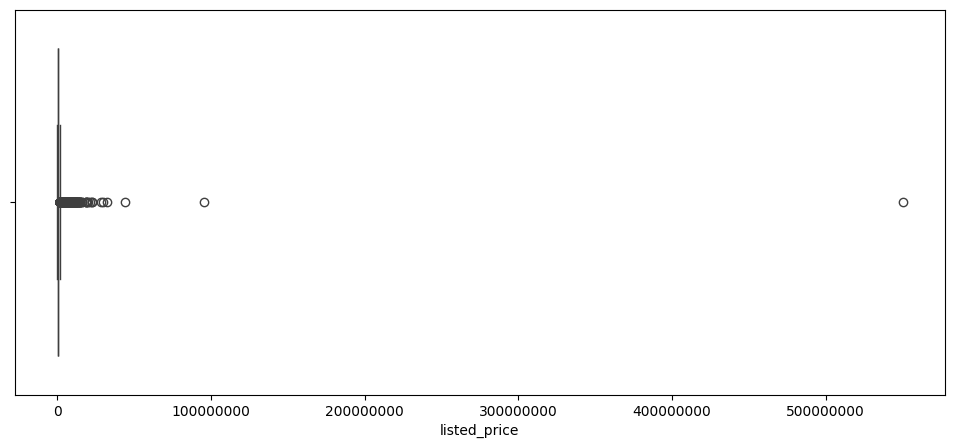

In [3]:
# Visualize the target feature (price)
plt.figure(figsize=(12, 5))
sns.boxplot(data=df4, x='listed_price')
plt.ticklabel_format(style='plain', axis='x')
plt.show()

The listed price is heavily influenced by the outliers which requires further investigation.

In [4]:
# Investigate the outliers in target feature
df4[df4['listed_price']>=5000000][['loc', 'myear', 'fuel', 'km', 'oem', 'model', 'variant', 'City', 
                                   'listed_price', 'discountValue']].sort_values(by='listed_price')

,loc,myear,fuel,km,oem,model,variant,City,listed_price,discountValue
13190,tilak nagar east,2019,diesel,29000.0,volvo,volvo xc60,inscription d5,new delhi,5000000.0,0
10878,pune city,2018,petrol,62142.0,audi,audi a4,30 tfsi technology,pune,5000000.0,0
7360,matunga west,2018,diesel,36000.0,mercedes-benz,mercedes-benz e-class,exclusive e 220 d bsiv,mumbai,5000000.0,0
13211,bangalore city,2020,diesel,76049.0,volvo,volvo xc60,inscription d5,bangalore,5000000.0,0
9653,mahabir nagar,2016,diesel,34000.0,bmw,bmw 7 series,signature 730ld,new delhi,5000000.0,0
...,...,...,...,...,...,...,...,...,...,...
13634,NaN,2021,petrol,80000.0,lamborghini,lamborghini huracan evo,spyder rwd,jaunpur,29999999.0,0
2764,NaN,2020,petrol,5000.0,ferrari,ferrari 488 gtb,spider,agra,32570569.0,0
2766,NaN,2022,petrol,50000.0,ferrari,ferrari sf90 stradale,coupe v8,alwar,44425000.0,0
13638,NaN,2021,petrol,15000.0,rolls-royce,rolls-royce phantom,extended wheelbase,amritsar,95519530.0,0


There seems to be some erronous data where a Ford Ecosport is costing Rs 55 crores. Other records seems to be correct as the luxury cars will usually sell at higher costs.

In [5]:
# Find the non luxary cars having price more than 50 lacs
luxury_brands = ['mercedes-benz', 'volvo', 'porsche', 'bmw', 'jaguar', 'lamborghini', 'ferrari', 'maserati', 
                 'bentley', 'audi', 'aston martin', 'jeep', 'land rover', 'lexus', 'rolls-royce', 'mini']
df4[(df4['listed_price']>=5000000) & ~(df4['oem'].isin(luxury_brands))][['oem','model','listed_price']]

,oem,model,listed_price
1379,toyota,toyota vellfire,9300000.0
1404,toyota,toyota vellfire,10700000.0
2763,ford,ford mustang,7500000.0
2775,ford,ford mustang,6800000.0
2799,toyota,toyota land cruiser,9099999.0
3102,toyota,toyota land cruiser,9500000.0
3337,toyota,toyota vellfire,9900000.0
5091,ford,ford ecosport,550000555.0
16891,maruti,maruti ciaz,5500000.0
26248,honda,honda city,9750000.0


We could see three erronous data which is a Ford Ecosport costing Rs 55 cr, Maruti Ciaz costing Rs 55 lacs and Honda City costing Rs 97.5 lacs.

In [6]:
# Remove the erronous data from the dataset
df4.drop(index=[5091, 16891, 26248], axis=0, inplace=True)

In [7]:
# Check the null values and their percentage in the database
null_count = df4.isnull().sum()
null_percentage = (df4.isnull().sum() / len(df4) * 100).round(2)
df4_missing = pd.DataFrame({'Null Count': null_count, 'Null Percentage': null_percentage})
df4_missing[df4_missing['Null Percentage']>=50]

,Null Count,Null Percentage
Gross Weight,20888,55.24
Compression Ratio,27800,73.53
Ground Clearance Unladen,35658,94.31
Bore,25176,66.59
Stroke,37297,98.64


The above columns have majority of their values as null. So, these feature doesn't contribute much for the training. Hence, these features can be dropped.

In [8]:
# Convert the oem into Running letters and variants in upper case
df4['oem'] = df4['oem'].str.capitalize()
df4['variant'] = df4['variant'].str.upper()

In [9]:
df4['oem'].unique()

<ArrowStringArray>
[            'Maruti',              'Honda',            'Hyundai',
               'Tata',             'Toyota',              'Bajaj',
           'Mahindra',          'Chevrolet',                 'Mg',
      'Mercedes-benz',               'Mini',            'Renault',
             'Nissan',             'Datsun',                'Kia',
              'Force',               'Icml',      'Ashok leyland',
                'Bmw',              'Volvo',               'Audi',
              'Isuzu',            'Porsche',             'Jaguar',
        'Lamborghini',               'Ford',            'Ferrari',
                 'Dc',            'Bentley',       'Aston martin',
         'Volkswagen',              'Skoda',               'Jeep',
               'Fiat',         'Land rover',         'Mitsubishi',
 'Mahindra ssangyong',   'Mahindra renault',              'Lexus',
            'Citroen',   'Hindustan motors',            'Premier',
        'Rolls-royce',               'Opel'

In [10]:
# Match the oem name with that in the variant extraction function
df4['oem'] = df4['oem'].replace({'Maruti': 'Maruti Suzuki', 'Kia': 'KIA', 'Mg': 'MG', 
                                 'Icml': 'ICML', 'Mercedes-benz': 'Mercedes-Benz', 'Bmw': 'BMW', 
                                 'Aston martin': 'Aston Martin', 'Land rover': 'Land Rover', 
                                 'Hindustan motors': 'Ambassador', 'Rolls-royce':'Rolls-Royce', 
                                 'Mahindra renault': 'Renault', 'Mahindra ssangyong': 'Ssangyong'})

In [11]:
# Remove the oem name from the model
df4['model'] = df4['model'].str.split().str[1:].str.join(' ')

In [12]:
# Create a new column for variant and extract variant using the extraction function
df4['variant_extracted'] = df4.apply(lambda row: extract_variant(row['variant'], row['oem']), axis=1)
df4.head(1)

,usedCarSkuId,loc,myear,body,transmission,fuel,km,ip,images,imgCount,...,Compression Ratio,Alloy Wheel Size,Ground Clearance Unladen,Max Power Delivered,Max Power At,Max Torque Delivered,Max Torque At,Bore,Stroke,variant_extracted
0,7111bf25-97af-47f9-867b-40879190d800,gomti nagar,2016,hatchback,manual,cng,69162.0,0,[{'img': 'https://images10.gaadi.com/usedcar_i...,15,...,NaN,NaN,NaN,58.16,6200.0,77.0,3500.0,69.0,NaN,LXI


In [13]:
# Check for the null values in extracted variant column
null_variants = df4[df4['variant_extracted'].isna()][['oem', 'model', 'variant', 'variant_extracted']]
null_variants

,oem,model,variant,variant_extracted
34,Hyundai,santro,AT CNG,NaN
60,Honda,city,CNG,NaN
91,Honda,city,CNG,NaN
169,Hyundai,santro,AT CNG,NaN
180,Maruti Suzuki,omni,CNG,NaN
...,...,...,...,...
37291,Hyundai,verna,TRANSFORM VTVT,NaN
37359,Hyundai,verna,1.4 CX VTVT,NaN
37601,Honda,accord,2.4 A/T,NaN
37645,Honda,amaze,ACE EDITION PETROL BSIV,NaN


There are around 791 out of 37813 records where variant is not available, which is around 2% of the total data. So, this will not have much impact on the analysis and can be ignored.

In [14]:
# Apply the normalization function to the model and variant
df4['model'] = df4['model'].apply(normalize_variant).astype(str)
df4['variant_extracted'] = df4['variant_extracted'].apply(normalize_variant).astype(str)

In [15]:
# Fetch the number of owners
df4['no_of_owners'] = get_no_of_owners(df4['owner_type']).fillna(999).astype(int)
df4[['oem', 'model', 'variant', 'owner_type', 'no_of_owners']].head()

,oem,model,variant,owner_type,no_of_owners
0,Maruti Suzuki,WAGON R,LXI CNG,first,1
1,Maruti Suzuki,CELERIO,GREEN VXI,first,1
2,Honda,AMAZE,S PLUS I-VTEC,second,2
3,Maruti Suzuki,WAGON R,LXI CNG,second,2
4,Maruti Suzuki,ERTIGA,VXI CNG,first,1


In [16]:
# Fetch the engine capacity from dvn
df4['engine_capacity_cc'] = df4['dvn'].str.extract(r'(\d+\.\d+)', expand=False)
df4['engine_capacity_cc'].unique()

<ArrowStringArray>
[   nan,  '1.2',  '1.8',  '1.4',  '1.0',  '1.1',  '2.4',  '2.7',  '2.8',
  '2.5',  '1.5',  '2.0',  '1.3',  '3.0',  '1.7', '1.25',  '4.7',  '3.2',
  '2.2',  '1.6',  '1.9',  '4.8',  '4.2',  '3.6',  '4.4',  '5.0',  '2.6',
 '1.99', '1.05',  '3.5',  '2.3']
Length: 31, dtype: str

In [23]:
# Drop the duplicate columns
df4 = df4.drop(columns=['variant', 'exterior_color'])

### Preparing the Final Dataset

In [24]:
# Create the mapping for dataframe-4
column_mapping = {'oem': 'brand', 'variant_extracted': 'variant', 'body': 'body_type', 'myear': 'make_year', 
                  'km': 'km_driven', 'no_of_owners': 'previous_owners', 'fuel': 'fuel_type', 'Seats': 'seats', 
                  'Color': 'exterior_color', 'Length': 'length', 'Width': 'width', 'Height': 'height', 
                  'Wheel Base': 'wheel_base', 'Front Tread': 'front_tread', 'Rear Tread': 'rear_tread', 
                  'Kerb Weight': 'kerb_weight', 'Gear Box': 'gear_box', 'Drive Type': 'drive_type', 
                  'Steering Type': 'steering_type', 'Turning Radius': 'turning_radius', 
                  'Front Brake Type': 'front_brake_type', 'Rear Brake Type': 'rear_brake_type', 
                  'Cargo Volume': 'boot_space', 'Fuel Suppy System': 'fuel_supply_system', 
                  'Alloy Wheel Size': 'alloy_wheel_size', 'Max Power Delivered': 'max_power_delivered', 
                  'Max Power At': 'max_power_at', 'Max Torque Delivered': 'max_torque_delivered', 
                  'Max Torque At': 'max_torque_at' , 'listed_price': 'price'}

In [25]:
# Rename the columns
df4 = df4.rename(columns=column_mapping)

In [27]:
# Keep only required columns and create missing ones as NaN
df4 = get_final_dataset(df4)
df4.head()

,brand,model,variant,body_type,make_year,state,km_driven,transmission,previous_owners,fuel_type,...,front_brake_type,rear_brake_type,boot_space,fuel_supply_system,alloy_wheel_size,max_power_delivered,max_power_at,max_torque_delivered,max_torque_at,price
0,Maruti Suzuki,WAGON R,LXI,hatchback,2016,uttar pradesh,69162.0,manual,1,cng,...,ventilated disc,drum,180.0,NaN,NaN,58.16,6200.0,77.0,3500.0,370000.0
1,Maruti Suzuki,CELERIO,VXI,hatchback,2015,maharashtra,45864.0,manual,1,cng,...,ventilated disc,drum,235.0,Gasoline Port Injection,NaN,58.20,6000.0,78.0,3500.0,365000.0
2,Honda,AMAZE,S,sedan,2015,delhi,81506.0,manual,2,cng,...,disc,drum,400.0,NaN,NaN,86.70,6000.0,109.0,4500.0,421000.0
3,Maruti Suzuki,WAGON R,LXI,hatchback,2013,delhi,115893.0,manual,2,cng,...,ventilated disc,drum,NaN,Multi-Point Fuel Injection,13.0,58.20,6200.0,77.0,3500.0,240000.0
4,Maruti Suzuki,ERTIGA,VXI,muv,2022,maharashtra,18900.0,manual,1,cng,...,disc,drum,NaN,NaN,NaN,86.63,5500.0,121.5,4200.0,1175000.0


In [28]:
# Save the standardized dataset into local machine
df4.to_csv(r'.\Cleaned Datasets\dataset_4.csv', index=False)